# Simulation Environments

ARIEL provides several simulated environments for MuJoCo.
In this notebook we attempt to load and visualize them.
To make sure that the environments are working properly, and that they also look correct.
The last section shows the Perlin noise that the rugged terrains are made of.

In [1]:
# Standard library
import inspect
from typing import cast

In [2]:
from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    single_frame_renderer,
)
from ariel.simulators import compile_model

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

In [3]:
# Third-party imports
import mujoco
import numpy as np
from matplotlib import pyplot as plt
from rich.console import Console
from rich.table import Table

%matplotlib inline
console = Console()

In [4]:
# Ariel imports
from ariel.simulation import environments as envs
from ariel.simulation.environments import (
    BaseWorld,
    SimpleFlatWorld,
    heightmap_functions,
)

In [5]:
# Display available environments
num_of_envs = len(inspect.getmembers(envs, inspect.isclass))
table = Table(title=f"ARIEL-MuJoCo Environments (total: {num_of_envs})")
table.add_column("Name", justify="center", style="cyan bold", no_wrap=True)

for name, _ in inspect.getmembers(envs, inspect.isclass):
    table.add_row(name)

console.print(table)

 ARIEL-MuJoCo Environments  
         (total: 9)         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           Name           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ AmphitheatreTerrainWorld │
│        BaseWorld         │
│      CompoundWorld       │
│    CraterTerrainWorld    │
│       OlympicArena       │
│    RuggedTerrainWorld    │
│    RuggedTiltedWorld     │
│     SimpleFlatWorld      │
│    SimpleTiltedWorld     │
└──────────────────────────┘

## Worlds

ARIEL provides several prebuilt MuJoCo worlds.
In the code cells below we visualize them, each with the same test object:
a 0.2 m red box of 0.9 kg and a green ball of 0.1 kg, 1 kg in all,
inside the mass and density ranges that `compile_model` checks.

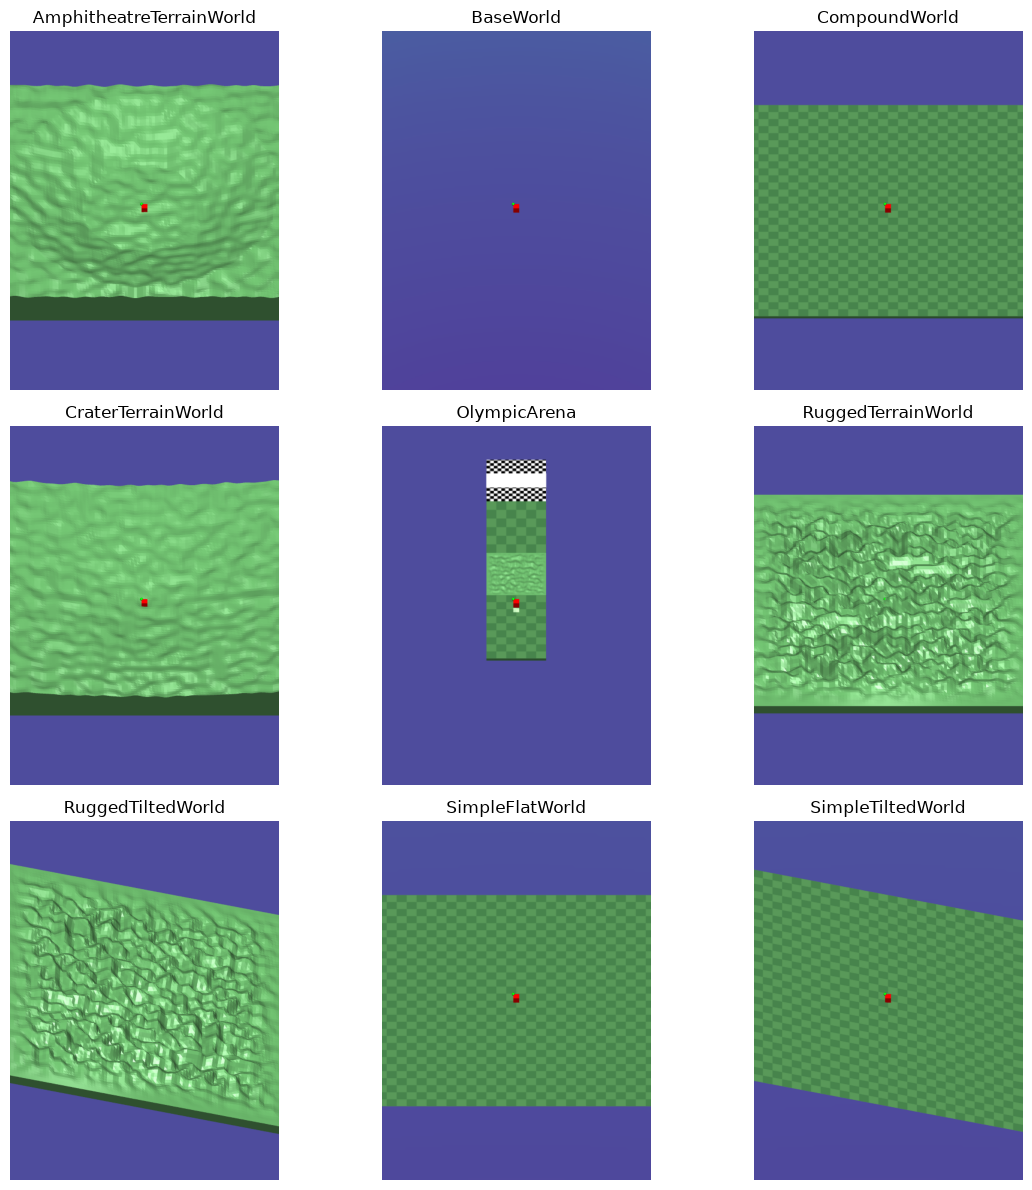

In [6]:
# Object to spawn in each environment
xml = r"""
<mujoco>
    <worldbody>
        <geom name="red_box" type="box" size=".1 .1 .1" rgba="1 0 0 1"
            mass=".9"/>
        <geom name="green_sphere" pos=".1 .1 .1" size=".05" rgba="0 1 0 1"
            mass=".1"/>
    </worldbody>
</mujoco>
"""

# Generate a grid of noise
fig_size = int(np.ceil(num_of_envs / 3))
fig, axes = plt.subplots(fig_size, 3, figsize=(12, 12))
ax = axes.ravel()
ax_filled = np.zeros(len(ax))
masses: dict[str, float] = {}
spreads: dict[str, float] = {}
for i, (name, cls) in enumerate(inspect.getmembers(envs, inspect.isclass)):
    # Instantiate the environment
    world = cast("type[BaseWorld]", cls)()

    # Spawn a test object to validate the environment
    test_object = mujoco.MjSpec.from_string(xml)
    world_spec = world.spawn(
        test_object,
        position=(0, 0, 0),
        rotation=(0, 0, 0),
    )

    # Compile the model and create data
    model = world.compile()
    data = mujoco.MjData(model)

    # Render a single frame
    img = single_frame_renderer(model, data, steps=1, cam_fovy=12)
    im = ax[i].imshow(img, origin="upper")
    ax[i].set_title(name)
    ax[i].axis("off")
    ax_filled[i] = 1
    masses[name] = float(model.body("robot1_world").mass[0])
    spreads[name] = float(np.asarray(img).std())

    # Clear memory
    del world, model, data, test_object, img

# remove empty subplots
for ax_i, filled in enumerate(ax_filled):
    if filled == 0:
        fig.delaxes(ax[ax_i])

plt.tight_layout()
plt.show()

In [7]:
# Checks: every world compiled with the 1 kg object and drew a picture
assert len(masses) == num_of_envs
assert all(np.isclose(mass, 1.0) for mass in masses.values()), masses
assert all(spread > 0 for spread in spreads.values()), spreads

## Height Field Functions

ARIEL provides several height field functions to create terrains.
In this below cell we visualize them as z-height maps.

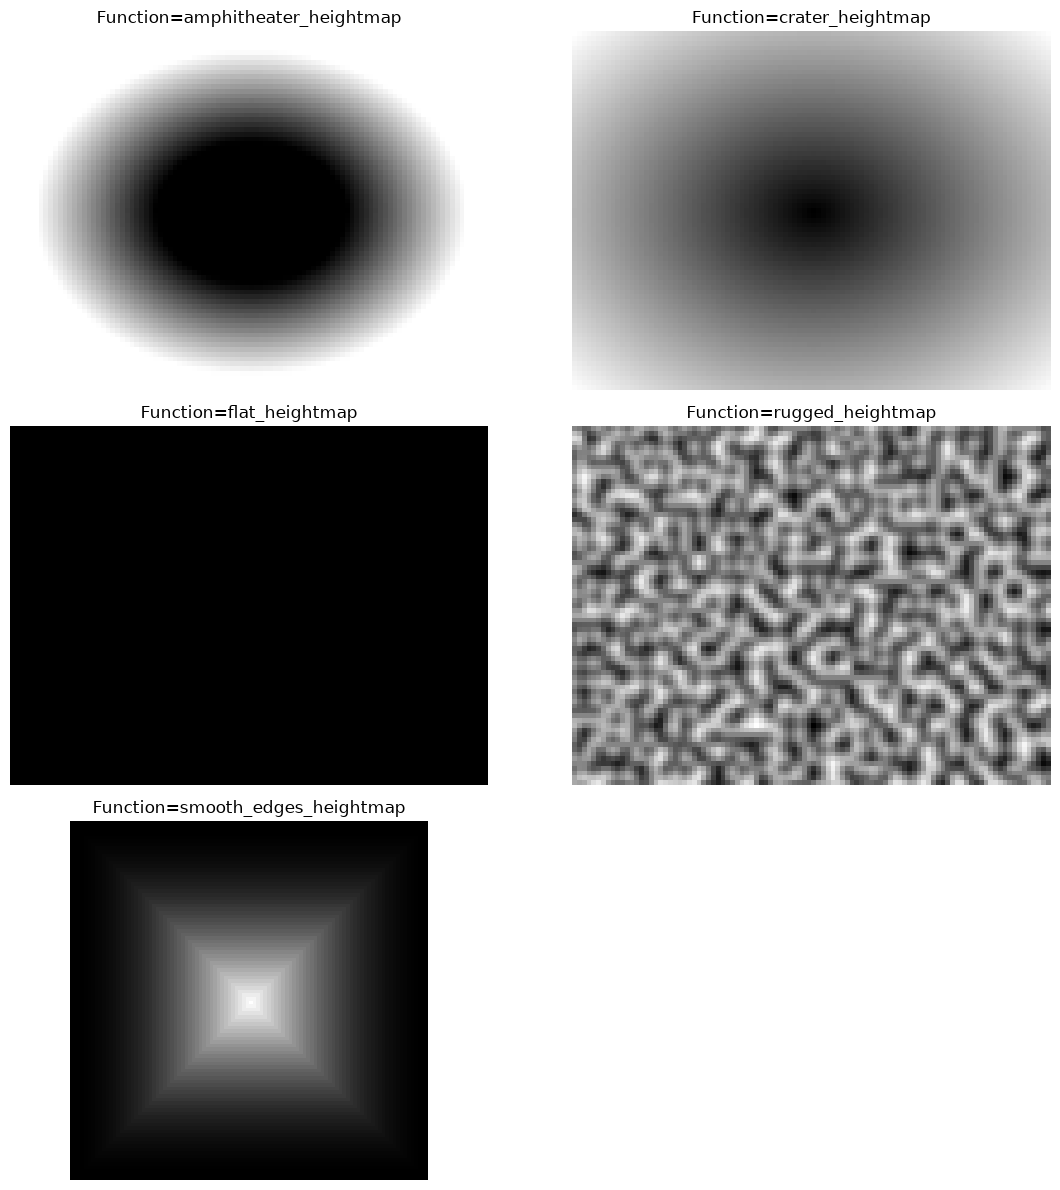

In [8]:
arguments = {
    "flat_heightmap": {
        "dims": (75, 100),
    },
    "rugged_heightmap": {
        "dims": (75, 100),
        "scale_of_noise": 4,
        "normalize": None,
    },
    "amphitheater_heightmap": {
        "dims": (75, 100),
        "ring_inner_radius": 0.2,
        "ring_outer_radius": 0.45,
        "cone_height": 1.0,
    },
    "crater_heightmap": {
        "dims": (75, 100),
        "crater_depth": 1.0,
        "crater_radius": 0.3,
    },
    "smooth_edges_heightmap": {
        "dims": (100, 100),
        "edge_width": 25,
    },
}

functions = inspect.getmembers(
    heightmap_functions,
    inspect.isfunction,
)
cols = 2
num_of_functions = len(functions)
fig_size = int(np.ceil(num_of_functions / cols))
fig, axes = plt.subplots(fig_size, cols, figsize=(12, 12))
ax = axes.ravel()
ax_filled = np.zeros(len(ax))
grids: dict[str, np.ndarray] = {}

# Loop through all functions in heightmap_functions.py
for i, (_, func) in enumerate(functions):
    # Call the function with default parameters
    grid = func(**arguments[func.__name__])
    grids[func.__name__] = grid
    im = ax[i].imshow(grid, cmap="gray", origin="upper")
    ax[i].set_title(f"Function={func.__name__}")
    ax[i].axis("off")
    ax_filled[i] = 1

# Remove empty subplots
for ax_i, filled in enumerate(ax_filled):
    if filled == 0:
        fig.delaxes(ax[ax_i])

plt.tight_layout()
plt.show()

In [9]:
# Checks: every function ran, at the size asked for, with no NaN or inf
assert set(grids) == set(arguments)
for func_name, grid in grids.items():
    assert grid.shape == arguments[func_name]["dims"], func_name
    assert np.isfinite(grid).all(), func_name
assert not grids["flat_heightmap"].any()

## Spawning

ARIEL world classes provide a method to spawn objects in the environment.

The class method `spawn` is responsible for adding an object to the environment at a specified position and orientation.

This method also attempts to correct the spawn position of the object to avoid collisions with the environment.

In the code cell below we visualize this functionality.

### Sawn Collision (boolean)

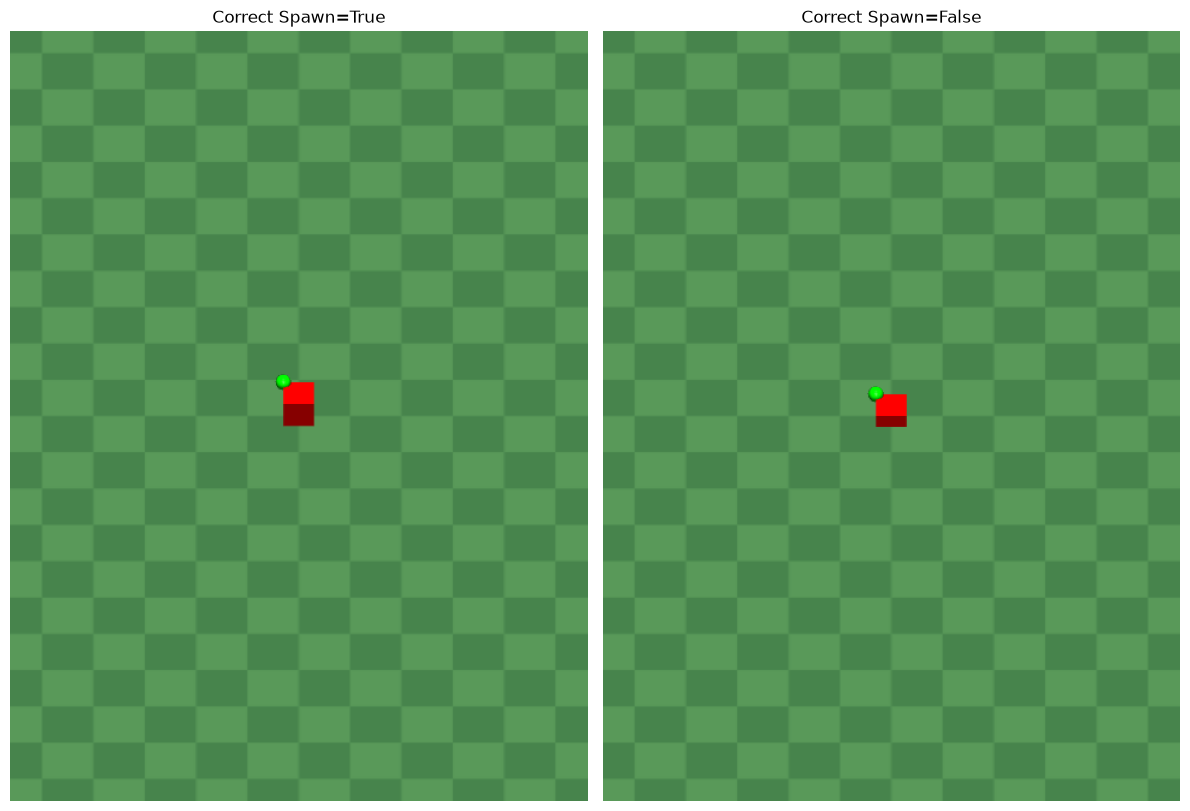

In [10]:
# Generate a grid of noise
spawn_modes = (True, False)
axis = (0, 0, 1, 2)  # x, x, y, z
num_of_modes = len(spawn_modes)
cols = 2
fig_size = int(np.ceil(num_of_modes / cols))
fig, axes = plt.subplots(fig_size, cols, figsize=(12, 12))
ax = axes.ravel()
ax_filled = np.zeros(len(ax))
box_bottoms: dict[bool, float] = {}

for i, mode in enumerate(spawn_modes):
    xml = r"""
    <mujoco>
    <worldbody>
        <geom name="red_box" type="box" size=".1 .1 .1" rgba="1 0 0 1"
            mass=".9"/>
        <geom name="green_sphere" pos=".1 .1 .1" size=".05" rgba="0 1 0 1"
            mass=".1"/>
    </worldbody>
    </mujoco>
    """
    # Instantiate the environment
    world = SimpleFlatWorld()

    # Spawn a test object to validate the environment
    test_object = mujoco.MjSpec.from_string(xml)
    world_spec = world.spawn(
        test_object,
        position=(0, 0, 0),
        rotation=(0, 0, 0),
        correct_collision_with_floor=mode,
    )

    # Compile the model and create data
    model = compile_model(world_spec)
    data = mujoco.MjData(model)

    # Render a single frame
    img = single_frame_renderer(model, data, steps=1)
    im = ax[i].imshow(img, origin="upper")
    ax[i].set_title(f"Correct Spawn={mode}")
    ax[i].axis("off")
    ax_filled[i] = 1
    box = model.geom("robot1_red_box").id
    box_bottoms[mode] = float(data.geom_xpos[box][2] - 0.1)

    # Clear memory
    del world, model, data, test_object, img

# Remove empty subplots
for ax_i, filled in enumerate(ax_filled):
    if filled == 0:
        fig.delaxes(ax[ax_i])

plt.tight_layout()
plt.show()

In [11]:
# Checks: with the correction the box rests 0.01 m above the floor (z = 0);
# without it the box is spawned half sunk, its bottom 0.1 m below
assert np.isclose(box_bottoms[True], 0.01, atol=0.005), box_bottoms
assert np.isclose(box_bottoms[False], -0.1, atol=0.01), box_bottoms

### Rotation (tuple of 3 floats)

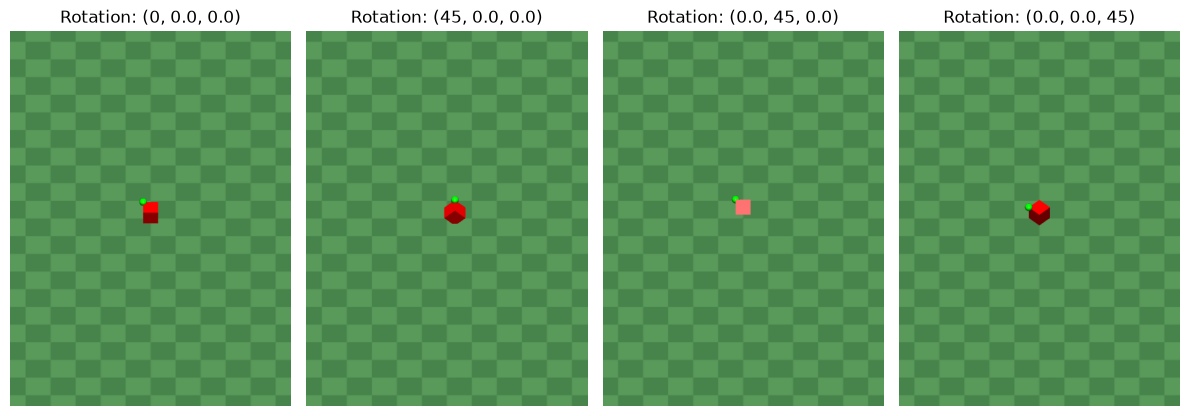

In [12]:
# Generate a grid of noise
angles = (0, 45, 45, 45)
axis = (0, 0, 1, 2)  # x, x, y, z
num_of_angles = len(angles)
cols = 4
fig_size = int(np.ceil(num_of_angles / cols))
fig, axes = plt.subplots(fig_size, cols, figsize=(12, 12))
ax = axes.ravel()
ax_filled = np.zeros(len(ax))
quats: list[np.ndarray] = []

for i, angle in enumerate(angles):
    xml = r"""
    <mujoco>
    <worldbody>
        <geom name="red_box" type="box" size=".1 .1 .1" rgba="1 0 0 1"
            mass=".9"/>
        <geom name="green_sphere" pos=".1 .1 .1" size=".05" rgba="0 1 0 1"
            mass=".1"/>
    </worldbody>
    </mujoco>
    """
    # Instantiate the environment
    world = SimpleFlatWorld()

    # Spawn a test object to validate the environment
    test_object = mujoco.MjSpec.from_string(xml)
    turn = [0.0, 0.0, 0.0]
    turn[axis[i]] = angle
    rotation = (turn[0], turn[1], turn[2])
    world_spec = world.spawn(
        test_object,
        position=(0, 0, 0),
        rotation=rotation,
    )

    # Compile the model and create data
    model = compile_model(world_spec)
    data = mujoco.MjData(model)

    # Render a single frame
    img = single_frame_renderer(model, data, steps=1)
    im = ax[i].imshow(img, origin="upper")
    ax[i].set_title(f"Rotation: {rotation}")
    ax[i].axis("off")
    ax_filled[i] = 1
    quats.append(data.xquat[model.body("robot1_world").id].copy())

    # Clear memory
    del world, model, data, test_object, img

# Remove empty subplots
for ax_i, filled in enumerate(ax_filled):
    if filled == 0:
        fig.delaxes(ax[ax_i])

plt.tight_layout()
plt.show()

In [13]:
# Checks: a turn of 45 degrees about an axis is the quaternion
# (cos 22.5, sin 22.5 on that axis); no turn is (1, 0, 0, 0)
half = np.deg2rad(45) / 2
assert np.allclose(quats[0], (1, 0, 0, 0), atol=1e-3)
for quat, turned in zip(quats[1:], axis[1:], strict=True):
    expected = np.zeros(4)
    expected[0] = np.cos(half)
    expected[turned + 1] = np.sin(half)
    assert np.allclose(quat, expected, atol=1e-3), quat

### Position (tuple of 3 floats)

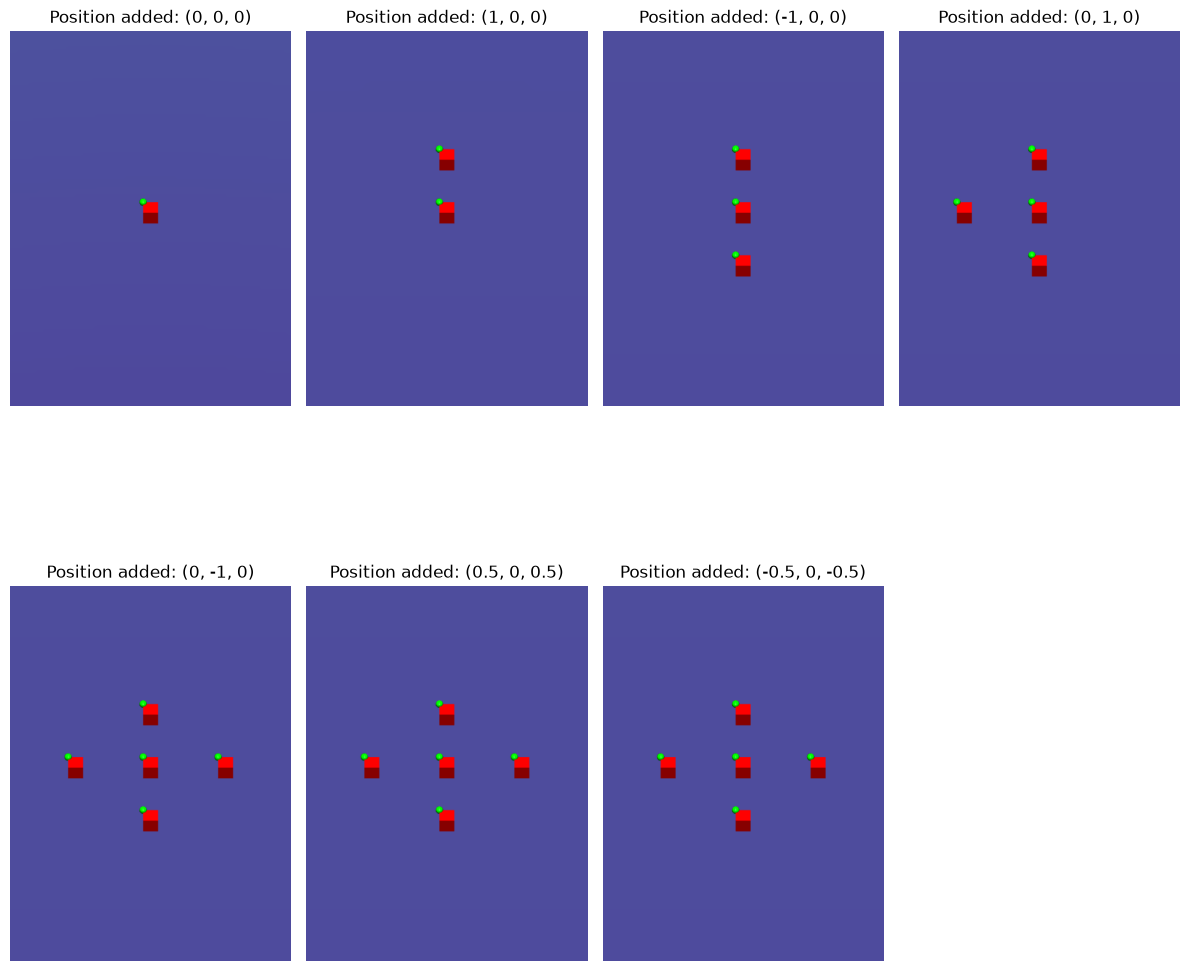

In [14]:
# Instantiate the environment: BaseWorld with nothing added
class EmptyWorld(BaseWorld):
    def _expand_spec(self) -> None:  # ruff: ignore[no-self-use]  # an override
        return


world = EmptyWorld()

# Object description
xml = r"""
<mujoco>
<worldbody>
    <geom name="red_box" type="box" size=".1 .1 .1" rgba="1 0 0 1"
        mass=".9"/>
    <geom name="green_sphere" pos=".1 .1 .1" size=".05" rgba="0 1 0 1"
        mass=".1"/>
</worldbody>
</mujoco>
"""

# Spawn positions
positions = [
    (0, 0, 0),
    (1, 0, 0),
    (-1, 0, 0),
    (0, 1, 0),
    (0, -1, 0),
    (0.5, 0, 0.5),
    (-0.5, 0, -0.5),
]

# Generate a grid of noise
num_of_positions = len(positions)
cols = 4
fig_size = int(np.ceil(num_of_positions / cols))
fig, axes = plt.subplots(fig_size, cols, figsize=(12, 12))
ax = axes.ravel()

# Spawn objects at all positions
ax_filled = np.zeros(len(ax))
placed: list[np.ndarray] = []
for i, position in enumerate(positions):
    # Spawn a test object to validate the environment
    test_object = mujoco.MjSpec.from_string(xml)
    world_spec = world.spawn(
        test_object,
        position=position,
        rotation=(0, 0, 0),
    )

    # Compile the model and create data
    model = compile_model(world_spec)
    data = mujoco.MjData(model)

    # Render a single frame
    img = single_frame_renderer(model, data, steps=1)
    im = ax[i].imshow(img, origin="upper")
    ax[i].set_title(f"Position added: {position}")
    ax[i].axis("off")
    ax_filled[i] = 1
    placed.append(data.xpos[model.body(f"robot{i + 1}_world").id].copy())

    # Clear memory
    del model, data, test_object, img

# Remove empty subplots
for ax_i, filled in enumerate(ax_filled):
    if filled == 0:
        fig.delaxes(ax[ax_i])

plt.tight_layout()
plt.show()

In [15]:
# Checks: each object lands where it was asked, in x and y; the spawn
# correction lifts every one by the same height
offsets = np.array(placed) - np.array(positions)
assert np.allclose(offsets[:, :2], 0, atol=1e-3), offsets
assert np.allclose(offsets[:, 2], offsets[0, 2], atol=1e-3), offsets

## Perlin Noise

`rugged_heightmap` and `OlympicArena` build their terrain from
`PerlinNoise`. Below, one seed drawn at growing scales: a larger scale
means smoother noise.

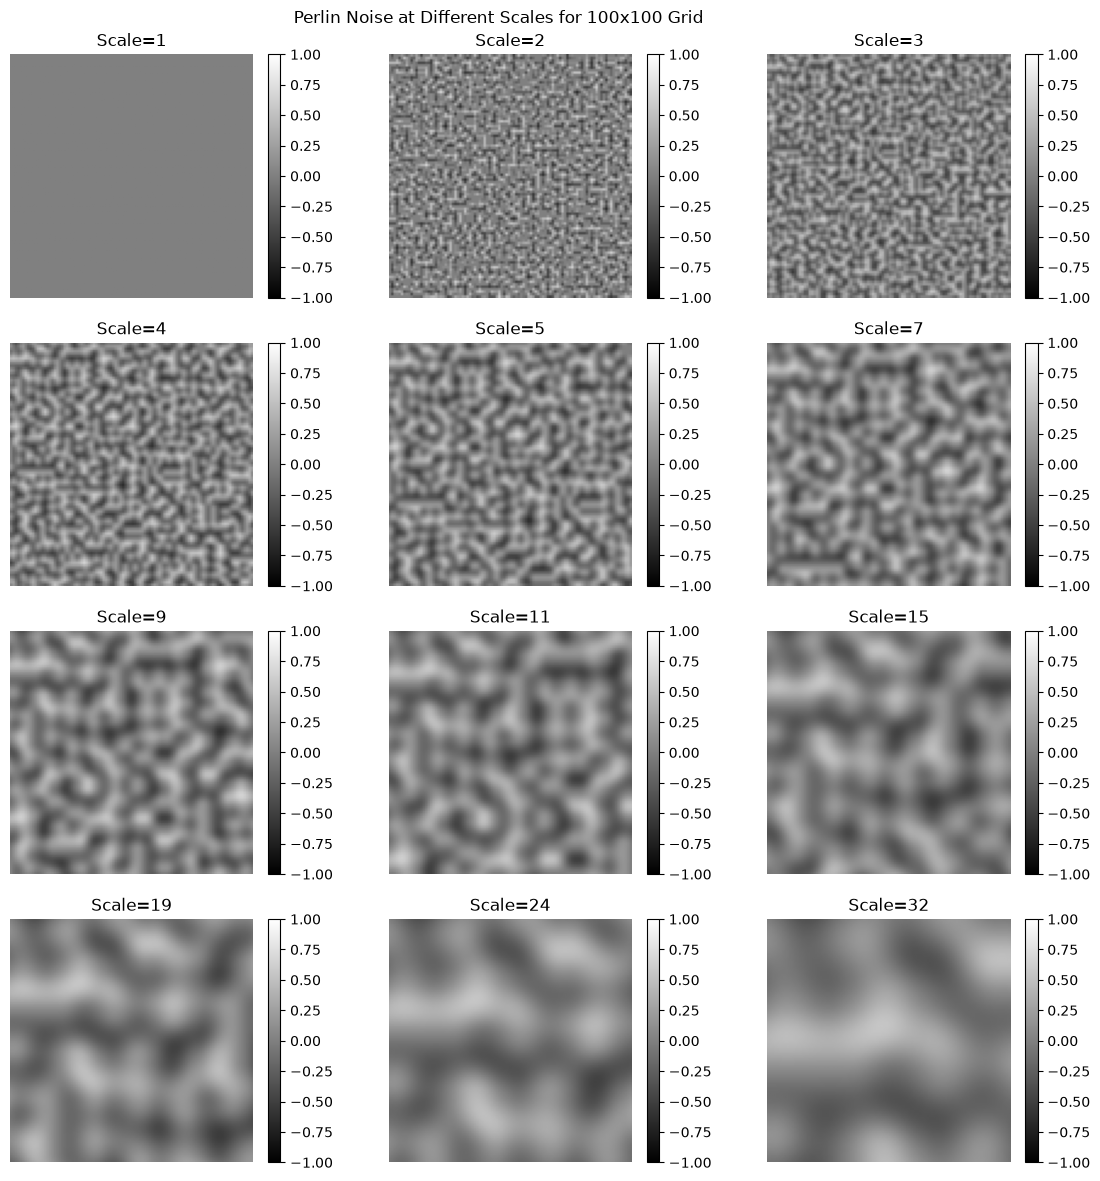

In [16]:
# Local libraries
from ariel.simulation.environments.noise_gen import PerlinNoise

# Perlin noise parameters
noise = PerlinNoise(seed=1234)
width, height = 100, 100

# Plot parameters
log_range = np.logspace(0, 5, num=15, base=2, dtype=int)
log_range = np.unique(log_range)  # Remove duplicates
cols = 3
num_of_modes = len(log_range)
fig_size = int(np.ceil(num_of_modes / cols))
fig, axes = plt.subplots(fig_size, cols, figsize=(12, 12))
ax = axes.ravel()
ax_filled = np.zeros(len(ax))

for i, scale in enumerate(log_range):
    grid = noise.as_grid(width, height, scale=scale)
    im = ax[i].imshow(grid, cmap="gray", origin="upper")
    im.set_clim(-1, 1)
    ax[i].axis("off")
    ax_filled[i] = 1
    ax[i].set_title(f"Scale={scale}")
    fig.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04)

# Remove empty subplots
for ax_i, filled in enumerate(ax_filled):
    if filled == 0:
        fig.delaxes(ax[ax_i])

fig.suptitle(f"Perlin Noise at Different Scales for {width}x{height} Grid")
plt.tight_layout()
plt.show()

In [17]:
# Checks: at scale 1 every pixel is a lattice corner, where Perlin noise
# is 0; above it the values stay inside [-1, 1] and grow smoother with
# the scale (smaller steps between neighbouring pixels)
grids = {int(s): noise.as_grid(width, height, scale=s) for s in log_range}
steps = [float(np.abs(np.diff(g, axis=1)).mean()) for g in grids.values()]
assert all(g.shape == (height, width) for g in grids.values())
assert not grids[1].any()
assert all(np.abs(g).max() <= 1 for g in grids.values())
assert (np.diff(steps[1:]) < 0).all(), steps